# Which value wins? One JSON object with a repeated key, through 14 readers

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/phoebefu6/phoebe-the-builder/blob/main/data-engineering-pro/duplicate-json-keys/demo.ipynb)
[![Binder](https://mybinder.org/badge_logo.svg)](https://mybinder.org/v2/gh/phoebefu6/phoebe-the-builder/main?labpath=data-engineering-pro/duplicate-json-keys/demo.ipynb)

`{"a":1,"a":2}` is legal JSON. RFC 8259 only says names SHOULD be unique, and that a reader of such an object may
keep the last value or report an error. So every reader here follows the spec, and they disagree. That matters the
moment two systems read the same payload: a validator that sees the first value and a consumer that acts on the
last one.

1. The engine
2. Which value each reader returns
3. A refund feed patched by string concatenation
4. Catching it before it loads
5. One engine, three entry points
6. The chart
7. Try your own

## 1. The engine

Extracted from `explore.py` and `evidence.py` at build time. Seeded (`Generator(215)`), every value fictional.
Node and jq join only when their binaries exist on the machine running this; the evidence file was made with both.

In [1]:
from __future__ import annotations

import io
import json
import os
import re
import shutil
import subprocess
import tempfile
import warnings
from itertools import combinations
from typing import Any, Callable, Dict, List, Optional

import matplotlib.pyplot as plt
import numpy as np


class _E:  # evidence.py refers to the engine as E
    pass

warnings.filterwarnings("ignore")


Lines = List[str]


Path = List[str]


def _dig(obj: Any, path: Path) -> Any:
    for k in path:
        obj = obj[k]
    return obj


def _per_line(loads: Callable[[str], Any]) -> Callable[[Lines, Path], List[Any]]:
    return lambda lines, path: [_dig(loads(s), path) for s in lines]


def _strict_pairs(pairs: List[Any]) -> Dict[str, Any]:
    seen: Dict[str, Any] = {}
    for k, v in pairs:
        if k in seen:
            raise ValueError(f"duplicate key {k!r}")
        seen[k] = v
    return seen


def _strict(s: str) -> Any:
    return json.loads(s, object_pairs_hook=_strict_pairs)


def _ujson(s: str) -> Any:
    import ujson

    return ujson.loads(s)


def _pydantic(s: str) -> Any:
    import pydantic

    return pydantic.TypeAdapter(dict).validate_json(s)


def _pyyaml(s: str) -> Any:
    import yaml

    return yaml.safe_load(s)


def _ruamel(s: str) -> Any:
    from ruamel.yaml import YAML

    return YAML(typ="safe").load(s)


def _frame(df: Any, path: Path) -> List[Any]:
    """A column reader turns path ['o','a'] into column 'o' then a dict lookup."""
    col = df[path[0]]
    vals = col.to_list() if hasattr(col, "to_list") else list(col)
    return [_dig(v, path[1:]) if len(path) > 1 else v for v in vals]


def _pandas(lines: Lines, path: Path) -> List[Any]:
    import pandas as pd

    return _frame(pd.read_json(io.StringIO("\n".join(lines) + "\n"), lines=True), path)


def _polars(lines: Lines, path: Path) -> List[Any]:
    import polars as pl

    return _frame(pl.read_ndjson(io.StringIO("\n".join(lines) + "\n")), path)


def _pyarrow(lines: Lines, path: Path) -> List[Any]:
    import pyarrow.json as pj

    rows = pj.read_json(io.BytesIO(("\n".join(lines) + "\n").encode())).to_pylist()
    return [_dig(r, path) for r in rows]


def _duck_file(lines: Lines, path: Path, ignore_errors: bool = False) -> List[Any]:
    import duckdb

    with tempfile.TemporaryDirectory() as d:
        f = os.path.join(d, "x.json")
        open(f, "w").write("\n".join(lines) + "\n")
        col = '"' + path[0] + '"' + "".join(f"['{k}']" for k in path[1:])
        q = f"select {col} from read_json('{f}'{', ignore_errors=true' if ignore_errors else ''})"
        return [r[0] for r in duckdb.sql(q).fetchall()]


def _duck_extract(lines: Lines, path: Path) -> List[Any]:
    import duckdb

    con = duckdb.connect()
    jp = "$." + ".".join(path)
    out = con.execute("select json_extract(unnest(?), ?)", [lines, jp]).fetchall()
    return [None if r[0] is None else json.loads(r[0]) for r in out]


def _cli(cmd: List[str]) -> Callable[[Lines, Path], List[Any]]:
    def run(lines: Lines, path: Path) -> List[Any]:
        p = subprocess.run(cmd, input="\n".join(lines) + "\n", capture_output=True, text=True, timeout=60)
        if p.returncode:
            raise RuntimeError(p.stderr.strip()[:120])
        return [_dig(json.loads(s), path) for s in p.stdout.splitlines() if s.strip()]

    return run


NODE = "require('readline').createInterface({input:process.stdin}).on('line',l=>{if(l.trim())console.log(JSON.stringify(JSON.parse(l)))})"


READERS: Dict[str, Callable[[Lines, Path], List[Any]]] = {
    "json": _per_line(json.loads),
    "ujson": _per_line(_ujson),
    "pydantic": _per_line(_pydantic),
    "PyYAML": _per_line(_pyyaml),
    "pandas read_json": _pandas,
    "polars read_ndjson": _polars,
    "duckdb json_extract": _duck_extract,
    "duckdb ignore_errors": lambda lines, path: _duck_file(lines, path, True),
    "json + strict hook": _per_line(_strict),
    "ruamel.yaml": _per_line(_ruamel),
    "pyarrow read_json": _pyarrow,
    "duckdb read_json": _duck_file,
}


if shutil.which("node"):
    READERS = {**dict(list(READERS.items())[:4]), "Node JSON.parse": _cli(["node", "-e", NODE]),
               **dict(list(READERS.items())[4:])}


if shutil.which("jq"):
    _i = list(READERS).index("pandas read_json")
    READERS = {**dict(list(READERS.items())[:_i]), "jq 1.6": _cli(["jq", "-c", "."]), **dict(list(READERS.items())[_i:])}


FIXTURES: Dict[str, Any] = {
    "top level": ('{"a":1,"a":2}', ["a"], 1, 2),
    "escaped key": ('{"a":1,"\\u0061":2}', ["a"], 1, 2),
    "nested": ('{"o":{"a":1,"a":2}}', ["o", "a"], 1, 2),
    "type change": ('{"a":1,"a":"x"}', ["a"], 1, "x"),
    "null last": ('{"a":1,"a":null}', ["a"], 1, None),
    "case only (not a dup)": ('{"A":1,"a":2}', ["a"], None, 2),
}


def classify(name: str, fixture: str) -> str:
    doc, path, first, last = FIXTURES[fixture]
    try:
        got = READERS[name]([doc], path)[0]
    except Exception:  # noqa: BLE001 - a refusal is a result
        return "refuse"
    if fixture.startswith("case"):
        return "ok" if got == 2 else f"WRONG ({got!r})"
    if got == last and type(got) is type(last):
        return "last"
    if got == first and type(got) is type(first):
        return "first"
    return f"other ({got!r})"


def matrix() -> Dict[str, Dict[str, str]]:
    return {r: {f: classify(r, f) for f in FIXTURES} for r in READERS}


def make_feed(seed: int = 215, n: int = 2000, rate: float = 0.03) -> Dict[str, Any]:
    """Orders as NDJSON. A refund job patches the status by string concatenation, so a refunded order carries
    'status' twice: the original first, the refund last. A third of the patches come from a writer that escapes
    every key character, so the second key is spelled "st\\u0061tus"."""
    rng = np.random.default_rng(seed)
    lines, refunded, amounts = [], [], []
    for i in range(n):
        amt = round(float(rng.lognormal(4.0, 0.8)), 2)
        st = str(rng.choice(["paid", "shipped", "delivered"]))
        body = f'{{"id":{100000 + i},"amount":{amt},"status":"{st}"'
        patched = bool(rng.random() < rate)
        if patched:
            key = '"st\\u0061tus"' if rng.random() < 1 / 3 else '"status"'
            body += f',{key}:"refunded"'
        lines.append(body + "}")
        refunded.append(patched)
        amounts.append(amt)
    return {"lines": lines, "refunded": refunded, "amounts": amounts}


def feed_study(feed: Dict[str, Any]) -> Dict[str, Dict[str, Any]]:
    truth_n = sum(feed["refunded"])
    truth_amt = round(sum(a for a, r in zip(feed["amounts"], feed["refunded"]) if r), 2)
    out: Dict[str, Dict[str, Any]] = {}
    for name, fn in READERS.items():
        try:
            st = fn(feed["lines"], ["status"])
        except Exception as e:  # noqa: BLE001
            out[name] = {"raised": type(e).__name__, "rows": 0, "refunds": 0, "amount": 0.0}
            continue
        ref = [s == "refunded" for s in st]
        out[name] = {
            "raised": "",
            "rows": len(st),
            "refunds": sum(ref),
            "amount": round(sum(a for a, r in zip(feed["amounts"], ref) if r), 2),
        }
    out["_truth"] = {"rows": len(feed["lines"]), "refunds": truth_n, "amount": truth_amt}
    return out


GREP = re.compile(r'"(\w+)"\s*:.*"\1"\s*:')


def detect(lines: Lines) -> Dict[str, int]:
    """Two pre-flight checks: a raw-text regex for a repeated quoted key, and json with a strict pairs hook."""
    grep = sum(bool(GREP.search(s)) for s in lines)
    hook = 0
    for s in lines:
        try:
            _strict(s)
        except ValueError:
            hook += 1
    return {"regex": grep, "strict hook": hook}


def check(doc: str) -> Dict[str, Any]:
    """For the app: one document through every reader at the first duplicated top-level key (or the first key)."""
    pairs = json.loads(doc, object_pairs_hook=lambda p: p)
    keys = [k for k, _ in pairs] if isinstance(pairs, list) else []
    dups = sorted({k for k in keys if keys.count(k) > 1})
    key = dups[0] if dups else (keys[0] if keys else None)
    one_line = " ".join(doc.split("\n")).strip()  # newlines are JSON whitespace; NDJSON readers need one line
    rows = []
    for name, fn in READERS.items():
        try:
            got: Any = fn([one_line], [key])[0]
            res = json.dumps(got)
        except Exception as e:  # noqa: BLE001
            res = f"refused ({type(e).__name__})"
        rows.append({"reader": name, "value of " + repr(key): res})
    return {"key": key, "dups": dups, "rows": rows}


E = _E()
E.__dict__.update(globals())

def study() -> Dict[str, Any]:
    feed = E.make_feed()
    return {"matrix": E.matrix(), "feed": E.feed_study(feed), "detect": E.detect(feed["lines"]),
            "n_lines": len(feed["lines"])}


def seeds(n: int = 30) -> Dict[str, Any]:
    """The detection gap and the refund count over 30 feeds. Reader behaviour itself is deterministic."""
    miss, refunds, hook_missed = [], [], []
    for s in range(1, n + 1):
        f = E.make_feed(seed=s)
        d = E.detect(f["lines"])
        miss.append(d["strict hook"] - d["regex"])
        refunds.append(sum(f["refunded"]))
        hook_missed.append(sum(f["refunded"]) - d["strict hook"])
    return {"regex_missed": miss, "refunds": refunds, "hook_missed": hook_missed}


def pairs(m: Dict[str, Dict[str, str]], fixture: str = "top level") -> Dict[str, int]:
    names = list(m)
    total = len(list(combinations(names, 2)))
    agree = sum(m[a][fixture] == m[b][fixture] for a, b in combinations(names, 2))
    return {"pairs": total, "disagree": total - agree}


def lines(r: Dict[str, Any], s: Dict[str, Any]) -> List[str]:
    m, fd, d = r["matrix"], r["feed"], r["detect"]
    fx = list(E.FIXTURES)
    out = [f"duplicate-json-keys evidence: {len(m)} readers, {len(fx)} fixtures, a {r['n_lines']:,}-line order "
           f"feed seeded Generator(215). Every value fictional.", ""]
    out.append("1. Which value each reader returns (fixture -> first / last / refuse)")
    out.append(f"   {'reader':<22}" + "".join(f"{f[:13]:<15}" for f in fx))
    for k, row in m.items():
        out.append(f"   {k:<22}" + "".join(f"{row[f][:13]:<15}" for f in fx))
    cls: Dict[str, List[str]] = {}
    for k, row in m.items():
        cls.setdefault(row["top level"], []).append(k)
    out.append("   top level: " + "; ".join(f"{c} {len(v)}" for c, v in cls.items()))
    p = pairs(m)
    out.append(f"   reader pairs that disagree on {{\"a\":1,\"a\":2}}: {p['disagree']} of {p['pairs']}")
    out.append("")
    t = fd["_truth"]
    out.append(f"2. The order feed: {t['refunds']} of {t['rows']:,} orders carry a refund patch "
               f"(status twice, refund last), ${t['amount']:,.2f} refunded")
    out.append(f"   {'reader':<22}{'rows read':>10}{'refunds':>9}{'refunded $':>13}  verdict")
    for k, v in fd.items():
        if k == "_truth":
            continue
        if v["raised"]:
            verdict = f"refused the whole file ({v['raised']})"
        elif v["refunds"] == t["refunds"]:
            verdict = "matches intent"
        else:
            verdict = f"missed {t['refunds'] - v['refunds']} refunds, ${t['amount'] - v['amount']:,.2f}, no error"
        out.append(f"   {k:<22}{v['rows']:>10,}{v['refunds']:>9}{v['amount']:>13,.2f}  {verdict}")
    out.append("")
    out.append(f"3. Pre-flight detection on the same feed: {d['strict hook']} duplicated lines")
    out.append(f"   regex for a repeated quoted key    {d['regex']:>3} found  (misses every \"st\\u0061tus\")")
    out.append(f"   json + object_pairs_hook (strict)  {d['strict hook']:>3} found")
    mi = s["regex_missed"]
    out.append(f"   over 30 seeds the regex missed {min(mi)}-{max(mi)} duplicated lines per feed "
               f"(feeds held {min(s['refunds'])}-{max(s['refunds'])}); the strict hook missed {min(s['hook_missed'])}-"
               f"{max(s['hook_missed'])}")
    out.append("")
    out.append("4. One engine, three entry points, two behaviours (duckdb, same document {\"a\":1,\"a\":2})")
    out.append(f"   read_json -> {m['duckdb read_json']['top level']}; read_json(ignore_errors=true) -> "
               f"{m['duckdb ignore_errors']['top level']}; json_extract -> {m['duckdb json_extract']['top level']}")
    out.append(f"   and {{\"A\":1,\"a\":2}} - not a duplicate - selecting column a returns "
               f"{m['duckdb read_json']['case only (not a dup)']}: identifiers are case-insensitive, 'a' became a_1")
    return out


def main() -> None:
    r, s = study(), seeds()
    out = lines(r, s)
    open("evidence.txt", "w").write("\n".join(out) + "\n")
    json.dump({"study": r, "seeds": s}, open("results.json", "w"), indent=1, default=str)
    print("\n".join(out))

In [2]:
r = study()
s = seeds()
out = lines(r, s)
section = lambda n: [l for l in "\n".join(out).split(f"\n{n}. ")[1].split("\n\n")[0].splitlines()]
print(out[0])

duplicate-json-keys evidence: 14 readers, 6 fixtures, a 2,000-line order feed seeded Generator(215). Every value fictional.


## 2. Which value each reader returns

Three camps on the plain case: last wins (json, ujson, pydantic, PyYAML, Node, jq, pandas), first wins (polars,
duckdb's `json_extract`, duckdb's `read_json` with `ignore_errors=true`), refuse (json with a strict
`object_pairs_hook`, ruamel.yaml, pyarrow, duckdb's `read_json`). polars is not even consistent with itself: it keeps
the first value at the top level, refuses a nested duplicate, and turns `1` then `"x"` into the string `'1'`. The last
column is not a duplicate at all - `A` and `a` are different names - and duckdb still returns the wrong one.

In [3]:
print("\n".join(section(1)))

Which value each reader returns (fixture -> first / last / refuse)
   reader                top level      escaped key    nested         type change    null last      case only (no  
   json                  last           last           last           last           last           ok             
   ujson                 last           last           last           last           last           ok             
   pydantic              last           last           last           last           last           ok             
   PyYAML                last           last           last           last           last           ok             
   Node JSON.parse       last           last           last           last           last           ok             
   jq 1.6                last           last           last           last           last           ok             
   pandas read_json      last           last           last           last           other (nan)    ok             
   po

## 3. A refund feed patched by string concatenation

A refund job appends `,"status":"refunded"` to the order line instead of rewriting it. Last-wins readers see every
refund. First-wins readers see none of them and say nothing. Strict readers refuse all 2,000 rows because of 46.

In [4]:
print("\n".join(section(2)))

The order feed: 46 of 2,000 orders carry a refund patch (status twice, refund last), $4,549.40 refunded
   reader                 rows read  refunds   refunded $  verdict
   json                       2,000       46     4,549.40  matches intent
   ujson                      2,000       46     4,549.40  matches intent
   pydantic                   2,000       46     4,549.40  matches intent
   PyYAML                     2,000       46     4,549.40  matches intent
   Node JSON.parse            2,000       46     4,549.40  matches intent
   jq 1.6                     2,000       46     4,549.40  matches intent
   pandas read_json           2,000       46     4,549.40  matches intent
   polars read_ndjson         2,000        0         0.00  missed 46 refunds, $4,549.40, no error
   duckdb json_extract        2,000        0         0.00  missed 46 refunds, $4,549.40, no error
   duckdb ignore_errors       2,000        0         0.00  missed 46 refunds, $4,549.40, no error
   json + strict 

## 4. Catching it before it loads

A grep for a repeated quoted key is the usual pre-flight check. It cannot see `"st\u0061tus"`, which every reader
decodes to `status`. Parsing with a strict pairs hook sees the decoded keys and catches every one.

In [5]:
print("\n".join(section(3)))

Pre-flight detection on the same feed: 46 duplicated lines
   regex for a repeated quoted key     30 found  (misses every "st\u0061tus")
   json + object_pairs_hook (strict)   46 found
   over 30 seeds the regex missed 11-26 duplicated lines per feed (feeds held 41-70); the strict hook missed 0-0


## 5. One engine, three entry points

The same duckdb process refuses the file, keeps the first value with `ignore_errors=true`, and keeps the first value
again through `json_extract`. Turning on `ignore_errors` to get a load through is how a refusal becomes a silent
first-wins.

In [6]:
print("\n".join(section(4)))

One engine, three entry points, two behaviours (duckdb, same document {"a":1,"a":2})
   read_json -> refuse; read_json(ignore_errors=true) -> first; json_extract -> first
   and {"A":1,"a":2} - not a duplicate - selecting column a returns WRONG (1): identifiers are case-insensitive, 'a' became a_1


## 6. The chart

The two-panel figure is `dupkeys.png` (built by `make_chart.py`). This is the feed alone: refunds each reader saw.

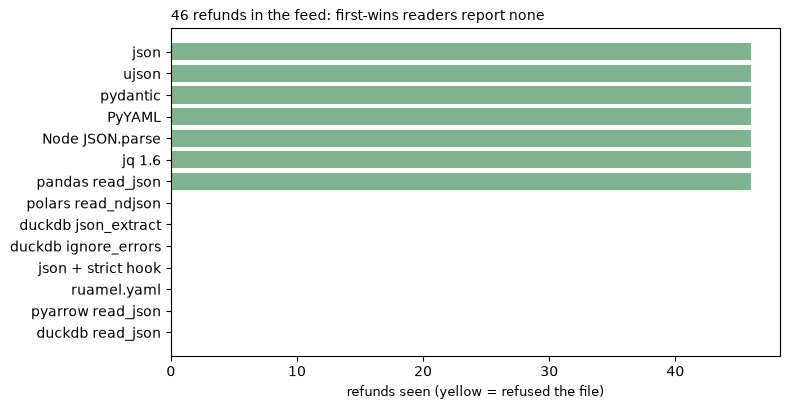

In [7]:
fd = r["feed"]
names = [k for k in fd if k != "_truth"]
vals = [fd[k]["refunds"] for k in names]
col = ["#f2c94c" if fd[k]["raised"] else "#7fb38f" if v == fd["_truth"]["refunds"] else "#c0392b"
       for k, v in zip(names, vals)]
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.barh(names, vals, color=col)
ax.invert_yaxis()
ax.set_xlabel("refunds seen (yellow = refused the file)", fontsize=9)
ax.set_title(f"{fd['_truth']['refunds']} refunds in the feed: first-wins readers report none", loc="left",
             fontsize=10)
plt.tight_layout()
plt.savefig("notebook_chart.png", dpi=120)
plt.show()

## Summary

- Duplicate keys are legal JSON; last-wins, first-wins and refusal are all spec-compliant, and they disagree.
- If any system in the path uses a different camp, a validator and a consumer can act on different values.
- Detect with a parser (`object_pairs_hook` that raises), never with a regex: escaped keys decode to the same name.
- Do not turn on `ignore_errors` to get a refused file through - in duckdb it switches to keeping the first value.

## 7. Try your own

In [8]:
# my_doc = '{"user":"ana","role":"viewer","role":"admin"}'
# for name, fn in READERS.items():
#     try:
#         print(f"{name:<22} {fn([my_doc], ['role'])[0]!r}")
#     except Exception as e:
#         print(f"{name:<22} refused ({type(e).__name__})")

---
Part of [phoebe-the-builder](https://github.com/phoebefu6/phoebe-the-builder). The Streamlit version lets you paste
a document and see every reader's answer: `pip install -r requirements.txt && streamlit run app.py`.